# 3. Hamiltonian Fast Marching

In this notebook, we run one solve, examine the value function and the path
extracted from its gradient, and show the effect of the obstacle cost on the
path. The planner does not search a graph of sampled configurations: it
propagates a front through the configuration space and extracts the optimal
path from the resulting value function.

**Summary**

1. [The value function](#1)
2. [Solving](#2)
3. [Reading a path off the gradient](#3)
4. [What the obstacle cost does](#4)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm import DEFAULT_VEHICLE
from shfm.figures import save

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

from shfm import from_image, Planner, REFERENCE_COEFFICIENTS
from shfm.solver import agd_location
from shfm.plotting import draw_map, draw_path, draw_footprints, draw_pose

print("agd in use:", os.path.relpath(agd_location(), ".."))

agd in use: external/agd/agd


<a id='1'></a>
## 1. The value function

Let $U(q)$ be the least cost of reaching configuration $q$ from the start. Under
mild assumptions it is the viscosity solution of the anisotropic eikonal
equation

$$ \max_{1 \le i \le I} \; \langle \nabla U(q), \dot p_i(q)\rangle_+ \;=\; c(q) $$

where the $\dot p_i(q)$ are the admissible velocities built in notebook 1 and
$c(q)$ is the local cost, the obstacle cost $C(q)$ of eq. (4.1) of the thesis;
the thesis writes the velocities $u_i(q)$ (eq. (4.18)). The equation says the
front advances fastest along
whichever admissible velocity best aligns with the gradient. Because those
velocities do not span every direction, the resulting metric is anisotropic,
which is what encodes the non-holonomic constraint.

The numerical scheme, the adaptive stencils it rests on and its convergence
proof are the work of J.-M. Mirebeau; the vendored `agd` library implements
the scheme, and notebook 9 works through two examples of it step by step.
The library also provides the `DubinsState` model, which J.-M. Mirebeau
wrote following our exchanges: it solves this equation for a vehicle with
several states and a cost on each change of state. This project adds the
four-wheel-steering control set, the four modes of notebook 4 with their
transition costs, and the collision model of notebook 2.

<a id='2'></a>
## 2. Solving

We solve, on the two-room map, the problem of the Two-Rooms comparison of
notebook 7, at the transition costs of the parameter study, $k_1 = 10$,
$k_2 = 50$, rather than the $(2, 3)$ of the comparisons. The campaign
plans on a 200 by 200 grid; we cover the same scene with 100 by 100 cells, so
the coordinates are halved. The vehicle starts in the upper room facing east,
towards its far wall, and must reach the lower room facing north. The path
crosses the whole scene: out of the upper room, down the hall on the left and
into the lower room.

The start mode is left free (`free_start_mode=True`): a vehicle at rest can
leave in any mode without a transition cost; here it leaves backward. Imposing
forward navigation on a path that leaves backward can produce back-and-forth
steps near the start of the extracted path, which notebook 5 deals with.

In [2]:
env = from_image("../data/maps/two_rooms.png", (100, 100), zoom=4, n_theta=100,
                 name="two_rooms")
print(env)

planner = Planner(env, k1=10, k2=50, **REFERENCE_COEFFICIENTS)
# The endpoints of the Two-Rooms campaign, (130, 140, 0) and (160, 30, pi/2)
# on its 200 x 200 grid, halved. The last component is the mode.
seed = [65, 70, 0, 0]
goal = [80, 15, np.pi / 2, 0]

import time
t0 = time.time()
result = planner.solve(seed=seed, tips=[goal], free_start_mode=True)
print("solved in %.2f s" % (time.time() - t0))
print("value function shape (x, y, theta, mode):", result.values.shape)

Environment(name='two_rooms', shape=(100, 100), n_theta=100, zoom=4, 1 unit = 0.25 m)
solved in 1.40 s
value function shape (x, y, theta, mode): (100, 100, 100, 4)


The value function lives on the full four-dimensional grid, too large to draw
at once. The figure below shows the simplest member of the family instead: the
value function of the bare scheme, an isotropic fast marching over
$(x, y, \theta)$ with unit speed, no kinematic constraint, no obstacle cost and
no mode axis. It is drawn by `generators/nav_function.py`, on the same map
read without transposition (see `data/maps/README.md`), from the root
$(30, 70, \pi/2)$ of that grid. On the grid of the solve above, that root is
the point $(70, 69, 0)$: in the upper room, about five units east of the start and
at the same heading. Its colour scale, the value, counts the 0.25 m of the
cells of the solve above.

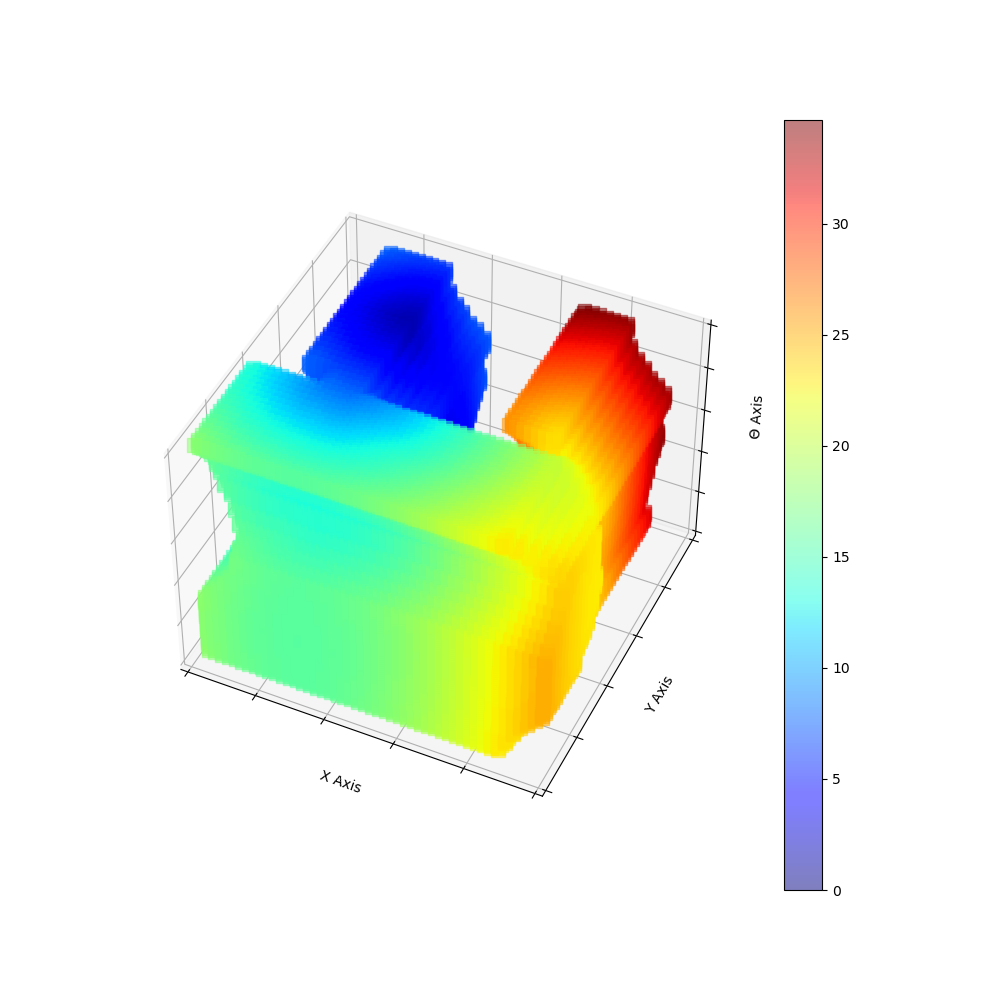

In [3]:
from shfm import generators as GEN
from IPython.display import Image, display

# The isotropic value function of the bare scheme.
# The script lives in generators/.
GEN.run("nav_function")
display(Image(GEN.figure_path("4WS_nav_function.png")))

<a id='3'></a>
## 3. Reading a path off the gradient

We obtain the path by following the gradient of $U$ back from the goal. The
solver has no random component: two solves of the same problem agree to within
the last digits of single precision (notebook 7, section 4). The backtracking
leaves the goal exactly and stops near the start rather than on it, 1.43 units
away here; notebook 5 closes that gap for the comparisons. The metrics printed
below are those of the comparisons. The last two, Bench-MR's deviations at the
goal, are kept for reference: the results use the Approach Heading Error
instead.

788 points, from (63.6, 70.2) to (80.0, 15.0), 1.43 units from the start


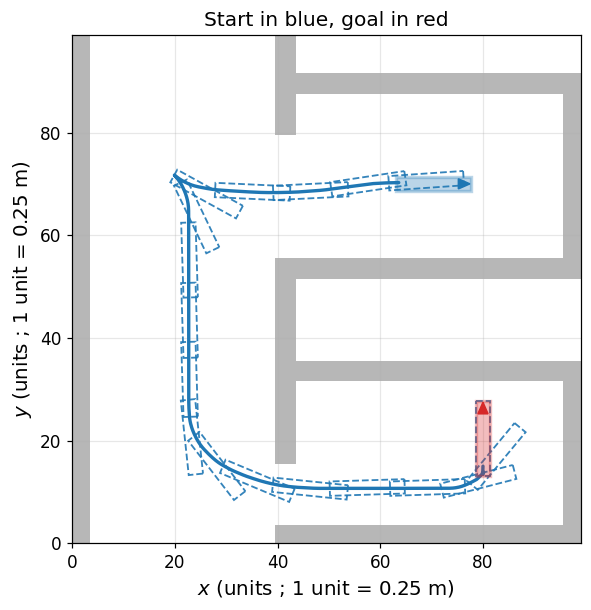

In [4]:
path = result.path(0)
print("%d points, from (%.1f, %.1f) to (%.1f, %.1f), %.2f units from the start"
      % (len(path), path[0, 0], path[0, 1], path[-1, 0], path[-1, 1],
         np.hypot(path[0, 0] - seed[0], path[0, 1] - seed[1])))

fig, ax = plt.subplots(figsize=(6.2, 6))
draw_map(ax, env)
draw_path(ax, path, color="tab:blue")
draw_footprints(ax, path, env.vehicle, env.zoom, n=18, color="tab:blue")
draw_pose(ax, *seed[:3], env.vehicle, env.zoom, "tab:blue")
draw_pose(ax, *goal[:3], env.vehicle, env.zoom, "tab:red")
ax.set_title("Start in blue, goal in red")
save(fig, "03_geodesic"); plt.show()

In [5]:
from shfm.metrics import summarize
m = summarize(path, env, goal)
for k, val in m.items():
    print("%-22s %8.3f" % (k, val))

length                  158.737
max_curvature             6.083
normalized_curvature      5.193
aol                       0.084
min_clearing              4.563
mean_clearing            13.117
swept_area_m2            54.883
approach_heading_error    1.024
angular_deviation         0.046
euclidean_deviation       0.380


<a id='4'></a>
## 4. What the obstacle cost does

Without obstacle cost, the front produces a geodesic, which runs along the
walls wherever that is shorter. Industrial use requires a margin, so the local
cost is raised near obstacles. Raising it without bound has a drawback of its
own: the path moves to the middle of any open area, which lengthens it without
a gain in safety. The cost is therefore capped, by default at the vehicle
length.

On the grid of the solve above, the open areas of Two-Rooms are barely wider
than twice the cap, and the cap changes the path little. Below, we keep the
map and the problem and make the vehicle half as large relative to the map:
the same image at zoom 2, where one unit is 0.5 m and the cap is 7.3 units.
Where the clearance exceeds the cap, the capped cost no longer decreases.

Environment(name='two_rooms', shape=(100, 100), n_theta=100, zoom=2, 1 unit = 0.5 m)
cap 7.3 units; clearance above it on 36.9% of the free configurations


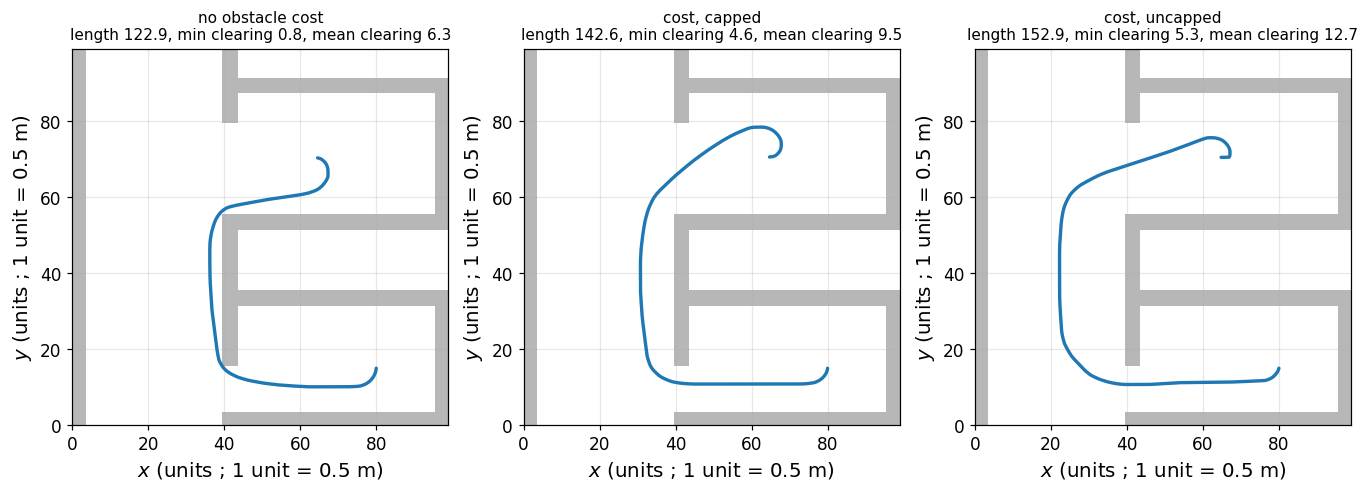

zoom 4: capped 158.7 units, uncapped 160.1 units


In [6]:
# The same map with a vehicle half as large relative to it.
env2 = from_image("../data/maps/two_rooms.png", (100, 100), zoom=2, n_theta=100,
                  name="two_rooms")
cap = env2.vehicle.length * env2.zoom
over = (env2.walls3_dist > cap) & ~env2.walls3
print(env2)
print("cap %.1f units; clearance above it on %.1f%% of the free configurations"
      % (cap, 100 * over.sum() / (~env2.walls3).sum()))

variants = [("no obstacle cost", dict(obstacle_cost=False, saturate=False)),
            ("cost, capped",     dict(obstacle_cost=True,  saturate=True)),
            ("cost, uncapped",   dict(obstacle_cost=True,  saturate=False))]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, (name, kw) in zip(axes, variants):
    p = Planner(env2, k1=10, k2=50, **kw, **REFERENCE_COEFFICIENTS)
    r = p.solve(seed=seed, tips=[goal], free_start_mode=True)
    g = r.path(0)
    draw_map(ax, env2)
    draw_path(ax, g, color="tab:blue")
    d = summarize(g, env2, goal)
    ax.set_title("%s\nlength %.1f, min clearing %.1f, mean clearing %.1f"
                 % (name, d["length"], d["min_clearing"], d["mean_clearing"]),
                 fontsize=10)
save(fig, "03_obstacle_cost"); plt.show()

# Back on the grid of the solve above, with the vehicle at zoom 4.
uncapped = Planner(env, k1=10, k2=50, saturate=False, **REFERENCE_COEFFICIENTS).solve(
    seed=seed, tips=[goal], free_start_mode=True).path(0)
print("zoom 4: capped %.1f units, uncapped %.1f units"
      % (summarize(path, env, goal)["length"], summarize(uncapped, env, goal)["length"]))

Without the obstacle cost the path runs along the walls, 0.8 units from them
at the closest, and keeps to the inner side of the hall. With the capped cost
it keeps at least 4.6 units away. Further from the walls than the cap the cost
is flat, and the path crosses the hall on the side of the doors, which is the
shortest way through it. Without the cap the cost keeps
decreasing towards the middle of the hall, and the path goes there:
152.9 units against 142.6, for a closest approach to the walls of 5.3
units against 4.6. At this scale the vehicle turns round inside the upper room,
driving forward, on all three paths, instead of backing out of it.

With the vehicle at zoom 4, as in the solve above, the two paths with the cost
have nearly the same length: 158.7 and 160.1 units. Section 6 of notebook 6
compares eight caps on three scenes.

---

Previous: [2. Collision and configuration space](02_collision_and_configuration_space.ipynb)
Next: [4. The state system](04_state_system.ipynb)